# 

In [1]:
# ==============================================================================
# CROP DISEASE DETECTION — FULL PIPELINE (Modules 1-7)
# Run this in a single Kaggle notebook. Paste each "# === MODULE N ===" section
# into its own cell, or run as one script.
#
# Fixes applied vs. the previous version:
#   1. Near-duplicate detection via perceptual hashing (not just exact MD5 dupes)
#   2. EDA step added before splitting (class counts, sample grid, image stats)
#   3. Group-aware split: near-duplicate clusters kept together across splits
#   4. Dataset-specific normalization (computed from our own training data,
#      not borrowed ImageNet stats — there's no pretrained backbone anymore)
#   5. Confusion matrix: added technique 4 (flagging + templated annotation
#      of notable off-diagonal confusions)
#   6. Resize: kept as plain square resize (224x224) — a deliberate choice,
#      consistent with the "keep preprocessing simple" decision. Note: this
#      stretches non-square images rather than preserving aspect ratio. If a
#      visual check of your images shows significant distortion, aspect-
#      preserving padding can be swapped in here instead.
# ==============================================================================

# === MODULE 1: REPRODUCIBILITY & ENVIRONMENT ===
import os
import random
import copy
import subprocess
from collections import defaultdict

from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# imagehash is used for near-duplicate detection (Fix #1). Install if missing.
try:
    import imagehash
except ImportError:
    subprocess.run(["pip", "install", "-q", "imagehash"], check=True)
    import imagehash

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


# === MODULE 2: DATA ACQUISITION ===
PLANTVILLAGE_DIR = "/kaggle/working/PlantVillage-Dataset"
if not os.path.exists(PLANTVILLAGE_DIR):
    print("Cloning raw PlantVillage repository from GitHub...")
    subprocess.run([
        "git", "clone", "https://github.com/spMohanty/PlantVillage-Dataset.git", PLANTVILLAGE_DIR
    ], check=True)
    print("PlantVillage dataset cloned successfully.")

CLASSES = [
    # Corn Classes (Block 1)
    'Corn_Cercospora_Gray_Leaf_Spot',
    'Corn_Common_Rust',
    'Corn_Northern_Leaf_Blight',
    'Corn_Healthy',
    # Rice Classes (Block 2)
    'Rice_Bacterial_Leaf_Blight',
    'Rice_Brown_Spot',
    'Rice_Leaf_Blast',
    'Rice_Leaf_Scald',
    'Rice_Sheath_Blight',
    'Rice_Healthy'
]
class_to_idx = {cls_name: i for i, cls_name in enumerate(CLASSES)}

data_directory_mapping = {
    'Corn_Cercospora_Gray_Leaf_Spot': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn___Cercospora_leaf_spot Gray_leaf_spot'),
    'Corn_Common_Rust': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn___Common_rust_'),
    'Corn_Northern_Leaf_Blight': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn___Northern_Leaf_Blight'),
    'Corn_Healthy': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn___healthy'),
    'Rice_Bacterial_Leaf_Blight': '/kaggle/input/rice-disease-dataset/Bacterial_leaf_blight',
    'Rice_Brown_Spot': '/kaggle/input/rice-disease-dataset/Brown_spot',
    'Rice_Leaf_Blast': '/kaggle/input/rice-disease-dataset/Leaf_blast',
    'Rice_Leaf_Scald': '/kaggle/input/rice-disease-dataset/Leaf_scald',
    'Rice_Sheath_Blight': '/kaggle/input/rice-disease-dataset/Sheath_blight',
    'Rice_Healthy': '/kaggle/input/rice-disease-dataset/Healthy'
}


# === MODULE 3a: COLLECTION + NEAR-DUPLICATE DETECTION (Fix #1) ===
def compute_phash(filepath):
    """Perceptual hash — similar (not just byte-identical) images hash close together."""
    with Image.open(filepath) as img:
        return imagehash.phash(img.convert('RGB'))

def collect_and_group_data(data_dir_map, hash_distance_threshold=5):
    """
    Scans dataset directories, computes a perceptual hash per image, and
    assigns a 'group_id' such that near-duplicate images (hash distance <=
    threshold) share the same group. This group_id is later used to make
    sure near-duplicates never get split across train/val/test (Fix #3).
    """
    records = []
    for target_class, folder_path in data_dir_map.items():
        if not os.path.exists(folder_path):
            print(f"Warning: Directory not found: {folder_path}")
            continue
        for root, _, files in os.walk(folder_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    full_path = os.path.join(root, file)
                    try:
                        phash = compute_phash(full_path)
                    except Exception as e:
                        print(f"Skipping unreadable file {full_path}: {e}")
                        continue
                    records.append({
                        'filepath': full_path,
                        'label_name': target_class,
                        'label_idx': class_to_idx[target_class],
                        'phash': phash
                    })

    df = pd.DataFrame(records)
    print(f"Total images scanned: {len(df)}")

    # Cluster near-duplicates within each class (cross-class hash collisions
    # are not disease-relevant, so clustering is done per class).
    df['group_id'] = -1
    next_group_id = 0
    for label_idx, class_df in df.groupby('label_idx'):
        hashes = class_df['phash'].tolist()
        indices = class_df.index.tolist()
        assigned = {}
        for i, idx_i in enumerate(indices):
            if idx_i in assigned:
                continue
            assigned[idx_i] = next_group_id
            for j in range(i + 1, len(indices)):
                idx_j = indices[j]
                if idx_j in assigned:
                    continue
                if hashes[i] - hashes[j] <= hash_distance_threshold:
                    assigned[idx_j] = next_group_id
            next_group_id += 1
        for idx, gid in assigned.items():
            df.loc[idx, 'group_id'] = gid

    n_groups = df['group_id'].nunique()
    n_dupe_groups = df.groupby('group_id').size().gt(1).sum()
    print(f"Unique near-duplicate groups: {n_groups}")
    print(f"Groups containing 2+ images (i.e. had near-duplicates removed from being 'independent'): {n_dupe_groups}")
    return df

df_all = collect_and_group_data(data_directory_mapping)


# === MODULE 3b: EDA — CLASS COUNTS, SAMPLE GRID, IMAGE PROPERTIES (Fix #2) ===
print("\n--- Class Distribution ---")
class_counts_table = df_all['label_name'].value_counts().reindex(CLASSES)
print(class_counts_table)

plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts_table.values, y=class_counts_table.index)
plt.title("Class Distribution (Post-Deduplication)")
plt.xlabel("Image Count")
plt.tight_layout()
plt.savefig("eda_class_distribution.png")
plt.show()

print("\n--- Sample Grid Per Class ---")
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 3 * len(CLASSES)))
for i, cls in enumerate(CLASSES):
    samples = df_all[df_all['label_name'] == cls].sample(n=min(4, len(df_all[df_all['label_name'] == cls])), random_state=SEED)
    for j, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(row['filepath'])
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(cls, fontsize=8)
    for j in range(len(samples), 4):
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig("eda_sample_grid.png")
plt.show()

print("\n--- Image Property Check (resolution/aspect ratio sample) ---")
prop_sample = df_all.sample(n=min(200, len(df_all)), random_state=SEED)
sizes = []
for _, row in prop_sample.iterrows():
    with Image.open(row['filepath']) as img:
        sizes.append(img.size)  # (width, height)
widths, heights = zip(*sizes)
print(f"Width  -> min: {min(widths)}, max: {max(widths)}, mean: {np.mean(widths):.0f}")
print(f"Height -> min: {min(heights)}, max: {max(heights)}, mean: {np.mean(heights):.0f}")
aspect_ratios = [w / h for w, h in sizes]
print(f"Aspect ratio -> min: {min(aspect_ratios):.2f}, max: {max(aspect_ratios):.2f} "
      f"(1.0 = square; large spread here means the Resize-to-square step below will distort some images more than others)")


# === MODULE 3c: GROUP-AWARE STRATIFIED SPLIT (Fix #3) ===
def group_aware_stratified_split(df, test_size=0.30, val_ratio_of_temp=0.50, seed=SEED):
    """
    Splits the data 70/15/15 (by default) while:
      - keeping every near-duplicate group entirely within one split
      - keeping per-class proportions close to the target ratios
    This is a manual per-class group allocator since sklearn doesn't offer
    a single built-in stratified+grouped train/val/test split.
    """
    rng = random.Random(seed)
    train_idx, val_idx, test_idx = [], [], []

    for label_idx, class_df in df.groupby('label_idx'):
        groups = class_df.groupby('group_id')
        group_list = list(groups.groups.items())  # [(group_id, [row_indices]), ...]
        rng.shuffle(group_list)

        total_n = len(class_df)
        target_train = total_n * (1 - test_size)
        target_val = total_n * test_size * (1 - val_ratio_of_temp)
        # (target_test is whatever remains)

        running_train, running_val = 0, 0
        for gid, idxs in group_list:
            n = len(idxs)
            if running_train + n <= target_train or running_train == 0:
                train_idx.extend(idxs)
                running_train += n
            elif running_val + n <= target_val or running_val == 0:
                val_idx.extend(idxs)
                running_val += n
            else:
                test_idx.extend(idxs)

    train_df = df.loc[train_idx].reset_index(drop=True)
    val_df = df.loc[val_idx].reset_index(drop=True)
    test_df = df.loc[test_idx].reset_index(drop=True)
    return train_df, val_df, test_df

train_df, val_df, test_df = group_aware_stratified_split(df_all)

print(f"\nSplits -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
print("\nPer-class split breakdown:")
split_check = pd.DataFrame({
    'train': train_df['label_name'].value_counts().reindex(CLASSES).fillna(0),
    'val': val_df['label_name'].value_counts().reindex(CLASSES).fillna(0),
    'test': test_df['label_name'].value_counts().reindex(CLASSES).fillna(0),
})
print(split_check)

# Sanity check: confirm no group_id appears in more than one split
train_groups = set(train_df['group_id'])
val_groups = set(val_df['group_id'])
test_groups = set(test_df['group_id'])
overlap = (train_groups & val_groups) | (train_groups & test_groups) | (val_groups & test_groups)
assert len(overlap) == 0, f"Leakage detected: {len(overlap)} group(s) span multiple splits!"
print("\nLeakage check passed: no near-duplicate group spans multiple splits.")

# Class weights (computed on train split only)
class_counts = train_df['label_idx'].value_counts().sort_index().values
total_samples = len(train_df)
class_weights = total_samples / (len(CLASSES) * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)


# === MODULE 3d: DATASET-SPECIFIC NORMALIZATION STATS (Fix #4) ===
def compute_mean_std(df, sample_size=2000, img_size=224):
    """
    Computes per-channel mean/std from our own training images, since there's
    no pretrained backbone to borrow ImageNet stats from (Fix #4).
    """
    sample = df.sample(n=min(sample_size, len(df)), random_state=SEED)
    basic_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor()
    ])
    channel_sum = torch.zeros(3)
    channel_sq_sum = torch.zeros(3)
    n_pixels = 0

    for _, row in sample.iterrows():
        img = Image.open(row['filepath']).convert('RGB')
        tensor = basic_transform(img)
        channel_sum += tensor.sum(dim=[1, 2])
        channel_sq_sum += (tensor ** 2).sum(dim=[1, 2])
        n_pixels += tensor.shape[1] * tensor.shape[2]

    mean = channel_sum / n_pixels
    std = torch.sqrt(channel_sq_sum / n_pixels - mean ** 2)
    return mean.tolist(), std.tolist()

print("\nComputing dataset-specific normalization stats from training split...")
DATASET_MEAN, DATASET_STD = compute_mean_std(train_df)
print(f"Dataset mean: {DATASET_MEAN}")
print(f"Dataset std:  {DATASET_STD}")


# === MODULE 4: TRANSFORMS & DATASET PIPELINE ===
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=DATASET_MEAN, std=DATASET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=DATASET_MEAN, std=DATASET_STD)
])

class CropDiseaseDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = self.df.loc[idx, 'label_idx']
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

train_loader = DataLoader(CropDiseaseDataset(train_df, train_transform), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(CropDiseaseDataset(val_df, eval_transform), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(CropDiseaseDataset(test_df, eval_transform), batch_size=32, shuffle=False, num_workers=2)


# === MODULE 5: SCRATCH CNN ARCHITECTURE ===
class ScratchCropCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(ScratchCropCNN, self).__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)

model = ScratchCropCNN(num_classes=10).to(device)


# === MODULE 6: TRAINING ROUTINE (ADAM ONLY) ===
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999))
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

print("\n--- Starting Model Training (Adam Optimizer, LR=1e-3) ---")
best_loss = float('inf')
best_model_wts = copy.deepcopy(model.state_dict())
patience, patience_counter = 8, 0
epochs = 50

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    t_loss, t_acc = train_epoch(model, train_loader, optimizer, criterion)
    v_loss, v_acc = evaluate(model, val_loader, criterion)

    scheduler.step(v_loss)

    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_acc'].append(t_acc)
    history['val_acc'].append(v_acc)

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {t_loss:.4f} Acc: {t_acc:.4f} | Val Loss: {v_loss:.4f} Acc: {v_acc:.4f} | LR: {current_lr:.6f}")

    if v_loss < best_loss:
        best_loss = v_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1}")
            break

model.load_state_dict(best_model_wts)
torch.save(model.state_dict(), "crop_disease_scratch_cnn.pth")
print("Best model weights saved as 'crop_disease_scratch_cnn.pth'")

# Save normalization stats alongside the model — the Streamlit app needs
# these exact values to preprocess inference images identically (Module 8
# requires preprocessing consistency with training).
with open("normalization_stats.txt", "w") as f:
    f.write(f"mean={DATASET_MEAN}\nstd={DATASET_STD}\n")

# Training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title("Loss Curves")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Acc')
plt.plot(history['val_acc'], label='Val Acc')
plt.title("Accuracy Curves")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.savefig("training_curves.png")
plt.show()


# === MODULE 7: EVALUATION & EXPLAINABLE CONFUSION MATRIX ===
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

macro_f1 = f1_score(all_labels, all_preds, average='macro')
print(f"\nFinal Test Macro-F1 Score: {macro_f1:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=CLASSES))

# Technique 1 + 2: row-normalized, crop-grouped (CLASSES is already ordered
# corn-block then rice-block, so the axis order below gives that grouping)
cm = confusion_matrix(all_labels, all_preds, normalize='true')

# Technique 3: heatmap styling
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Row-Normalized Confusion Matrix (Grouped by Crop)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# Technique 4: flag and annotate notable off-diagonal confusions (Fix #5)
CONFUSION_FLAG_THRESHOLD = 0.10  # flag if >=10% of a class's images go to one wrong class
print("\n--- Notable Confusions (>= 10% of a class's true images) ---")
notable_confusions = []
for i, true_cls in enumerate(CLASSES):
    for j, pred_cls in enumerate(CLASSES):
        if i != j and cm[i, j] >= CONFUSION_FLAG_THRESHOLD:
            notable_confusions.append((true_cls, pred_cls, cm[i, j]))

if not notable_confusions:
    print("None found above threshold — classes are being cleanly separated.")
else:
    for true_cls, pred_cls, rate in sorted(notable_confusions, key=lambda x: -x[2]):
        same_crop = true_cls.split('_')[0] == pred_cls.split('_')[0]
        scope_note = "within the same crop (expected, visually similar diseases)" \
            if same_crop else "ACROSS crops (worth investigating — possible shortcut learning, e.g. background/leaf-shape cues rather than lesion patterns)"
        print(f"  {true_cls} -> predicted as {pred_cls}: {rate*100:.1f}% of true samples. "
              f"This confusion is {scope_note}.")
        # NOTE: the scope_note above is auto-generated from class/crop labels only.
        # Replace/extend with your own domain-specific reasoning (e.g. "both
        # present as elongated grey-brown lesions") once you've visually
        # compared the confused classes yourself.

Using device: cuda
Cloning raw PlantVillage repository from GitHub...


Cloning into '/kaggle/working/PlantVillage-Dataset'...
Updating files: 100% (182404/182404), done.


PlantVillage dataset cloned successfully.
Total images scanned: 0


KeyError: 'label_idx'

In [6]:
# Run this after the git clone, before anything else, to see the real folder names
color_root = os.path.join(PLANTVILLAGE_DIR, 'raw', 'color')
print("Folders found in raw/color:")
for folder in sorted(os.listdir(color_root)):
    print(f"  {folder}")

Folders found in raw/color:
  Apple___Apple_scab
  Apple___Black_rot
  Apple___Cedar_apple_rust
  Apple___healthy
  Blueberry___healthy
  Cherry_(including_sour)___Powdery_mildew
  Cherry_(including_sour)___healthy
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Corn_(maize)___Common_rust_
  Corn_(maize)___Northern_Leaf_Blight
  Corn_(maize)___healthy
  Grape___Black_rot
  Grape___Esca_(Black_Measles)
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
  Grape___healthy
  Orange___Haunglongbing_(Citrus_greening)
  Peach___Bacterial_spot
  Peach___healthy
  Pepper,_bell___Bacterial_spot
  Pepper,_bell___healthy
  Potato___Early_blight
  Potato___Late_blight
  Potato___healthy
  Raspberry___healthy
  Soybean___healthy
  Squash___Powdery_mildew
  Strawberry___Leaf_scorch
  Strawberry___healthy
  Tomato___Bacterial_spot
  Tomato___Early_blight
  Tomato___Late_blight
  Tomato___Leaf_Mold
  Tomato___Septoria_leaf_spot
  Tomato___Spider_mites Two-spotted_spider_mite
  Tomato___Target_Spot
  T

In [9]:
rice_root = '/kaggle/input/rice-disease-dataset'
print("Folders found in rice dataset root:")
for root, dirs, files in os.walk(rice_root):
    for d in dirs:
        print(f"  {os.path.join(root, d)}")

Folders found in rice dataset root:


In [10]:
data_directory_mapping = {
    'Corn_Cercospora_Gray_Leaf_Spot': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'),
    'Corn_Common_Rust': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___Common_rust_'),
    'Corn_Northern_Leaf_Blight': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___Northern_Leaf_Blight'),
    'Corn_Healthy': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___healthy'),
    'Rice_Bacterial_Leaf_Blight': '/kaggle/input/rice-disease-dataset/Bacterial_leaf_blight',
    'Rice_Brown_Spot': '/kaggle/input/rice-disease-dataset/Brown_spot',
    'Rice_Leaf_Blast': '/kaggle/input/rice-disease-dataset/Leaf_blast',
    'Rice_Leaf_Scald': '/kaggle/input/rice-disease-dataset/Leaf_scald',
    'Rice_Sheath_Blight': '/kaggle/input/rice-disease-dataset/Sheath_blight',
    'Rice_Healthy': '/kaggle/input/rice-disease-dataset/Healthy'
}

In [11]:
rice_root = '/kaggle/input/rice-disease-dataset'
for root, dirs, files in os.walk(rice_root):
    for d in dirs:
        print(os.path.join(root, d))

In [16]:
print("Contents of /kaggle/input:")
for name in os.listdir('/kaggle/input'):
    print(f"  {name}")

Contents of /kaggle/input:
  datasets


In [18]:
rice_root = '/kaggle/input/<exact_name_from_above>'
for root, dirs, files in os.walk(rice_root):
    for d in dirs:
        print(os.path.join(root, d))

In [19]:
for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/anshulm257
/kaggle/input/datasets/anshulm257/rice-disease-dataset
/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG
/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG/Leaf scald
/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG/Sheath Blight
/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG/Healthy Rice Leaf
/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG/Leaf Blast
/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG/Brown Spot
/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG/Bacterial Leaf Blight


In [21]:
RICE_ROOT = '/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG'
for cls_folder in ['Leaf scald', 'Sheath Blight', 'Healthy Rice Leaf', 'Leaf Blast', 'Brown Spot', 'Bacterial Leaf Blight']:
    path = os.path.join(RICE_ROOT, cls_folder)
    count = len(os.listdir(path))
    print(f"{cls_folder}: {count} images")

Leaf scald: 628 images
Sheath Blight: 632 images
Healthy Rice Leaf: 653 images
Leaf Blast: 634 images
Brown Spot: 646 images
Bacterial Leaf Blight: 636 images


Using device: cuda
Total images scanned: 7681
Unique near-duplicate groups: 7579
Groups containing 2+ images (i.e. had near-duplicates removed from being 'independent'): 78

--- Class Distribution ---
label_name
Corn_Cercospora_Gray_Leaf_Spot     513
Corn_Common_Rust                  1192
Corn_Northern_Leaf_Blight          985
Corn_Healthy                      1162
Rice_Bacterial_Leaf_Blight         636
Rice_Brown_Spot                    646
Rice_Leaf_Blast                    634
Rice_Leaf_Scald                    628
Rice_Sheath_Blight                 632
Rice_Healthy                       653
Name: count, dtype: int64


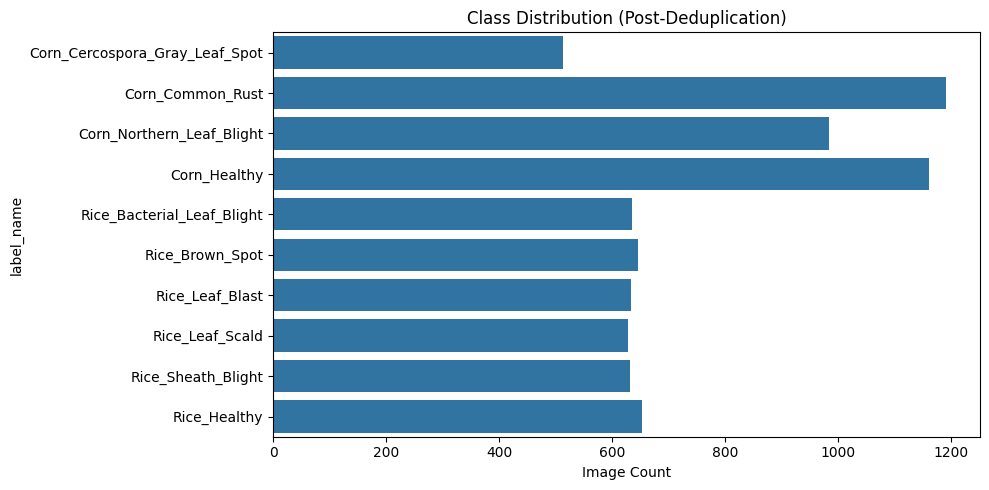


--- Sample Grid Per Class ---


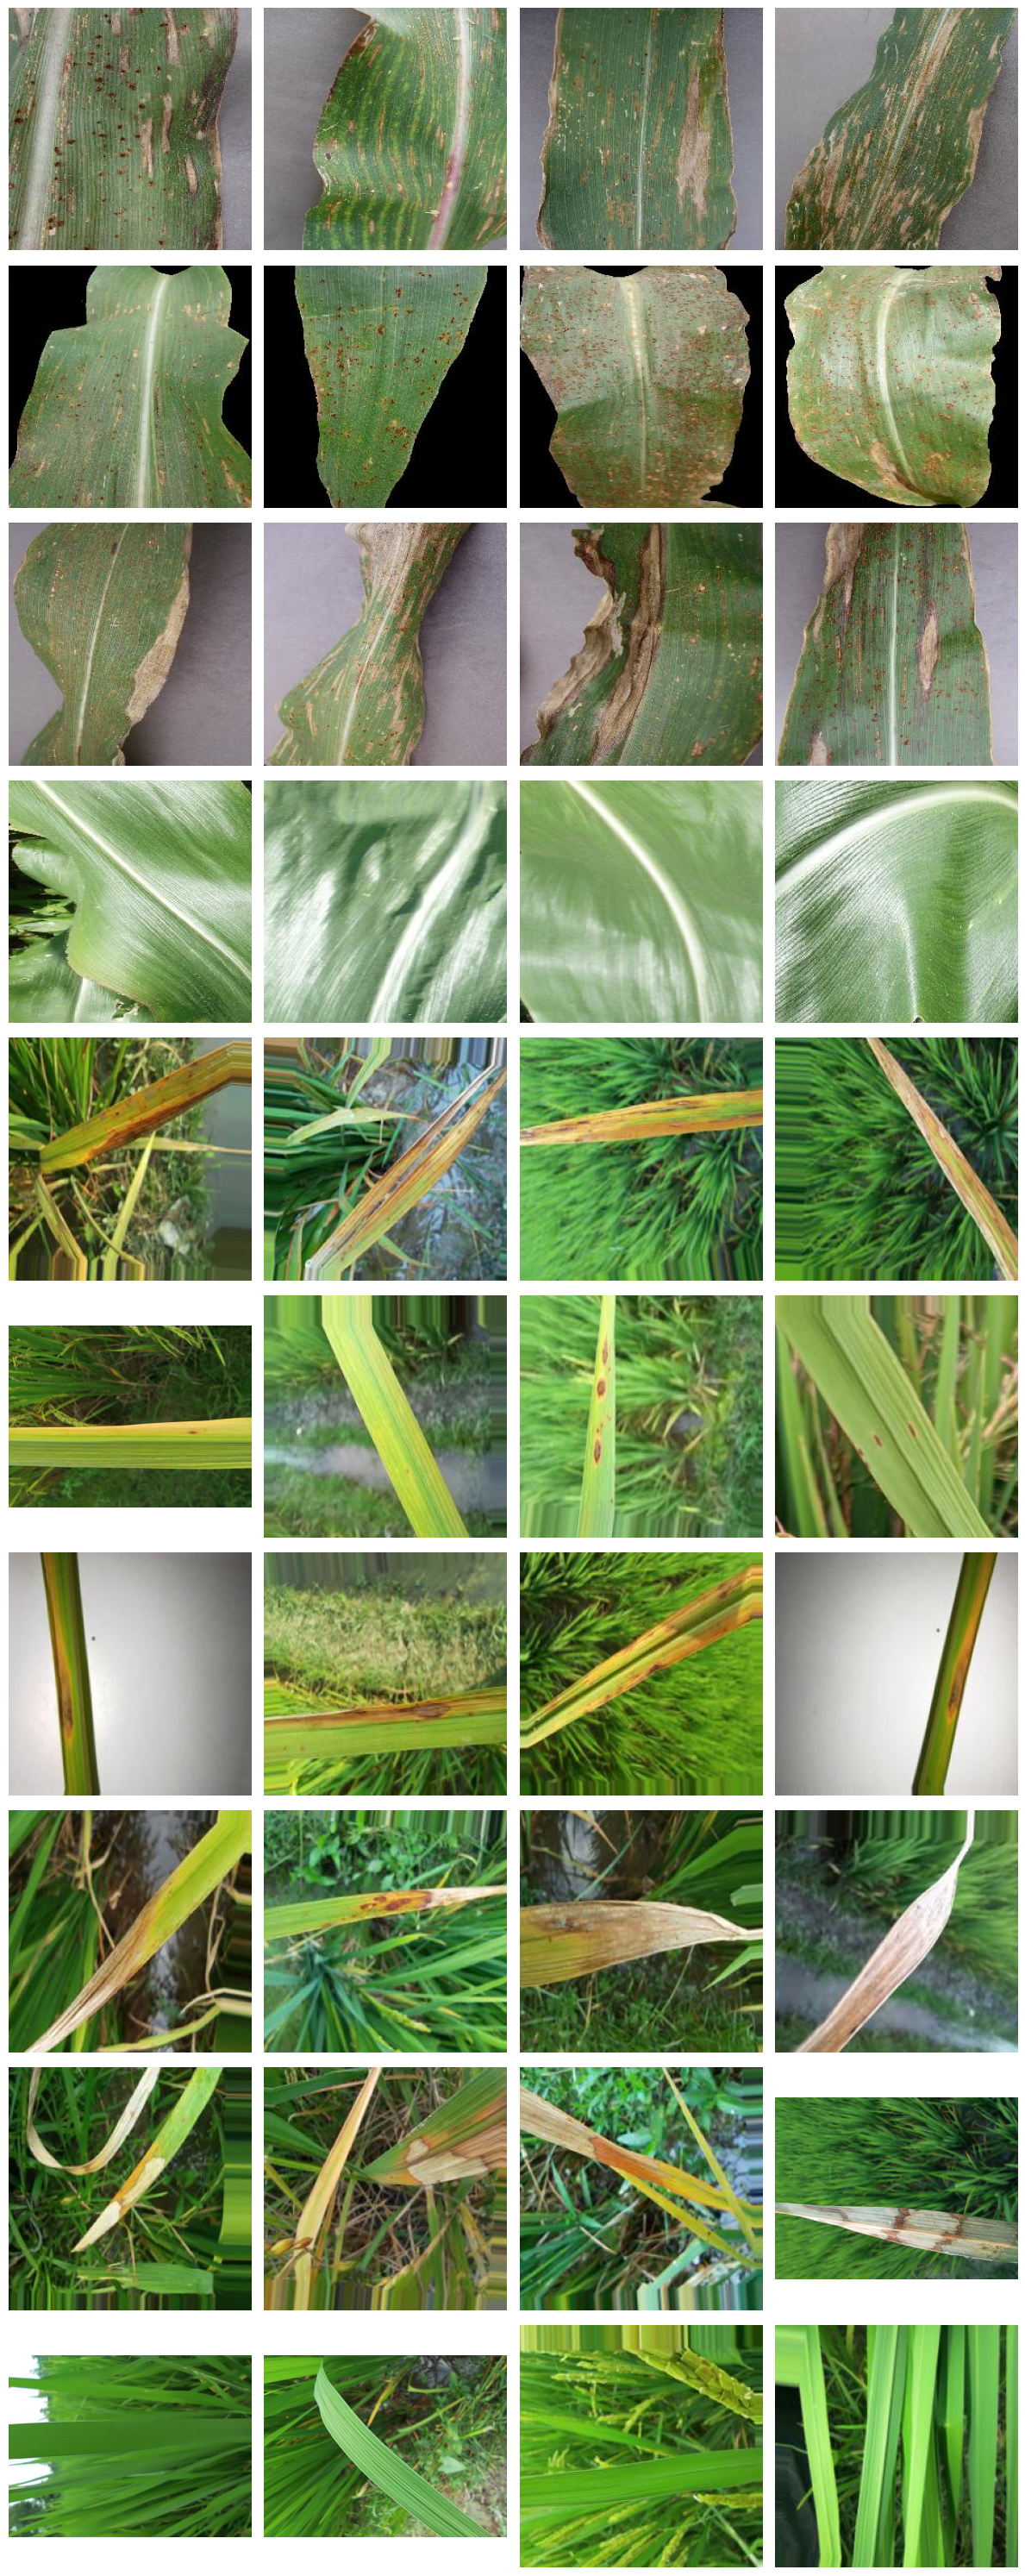


--- Image Property Check (resolution/aspect ratio sample) ---
Width  -> min: 224, max: 2448, mean: 416
Height -> min: 224, max: 3264, mean: 372
Aspect ratio -> min: 0.75, max: 1.33 (1.0 = square; large spread here means the Resize-to-square step below will distort some images more than others)

Splits -> Train: 5373, Val: 1146, Test: 1162

Per-class split breakdown:
                                train  val  test
label_name                                      
Corn_Cercospora_Gray_Leaf_Spot    359   76    78
Corn_Common_Rust                  834  178   180
Corn_Northern_Leaf_Blight         689  147   149
Corn_Healthy                      813  174   175
Rice_Bacterial_Leaf_Blight        445   95    96
Rice_Brown_Spot                   452   96    98
Rice_Leaf_Blast                   443   95    96
Rice_Leaf_Scald                   439   94    95
Rice_Sheath_Blight                442   94    96
Rice_Healthy                      457   97    99

Leakage check passed: no near-duplicate g

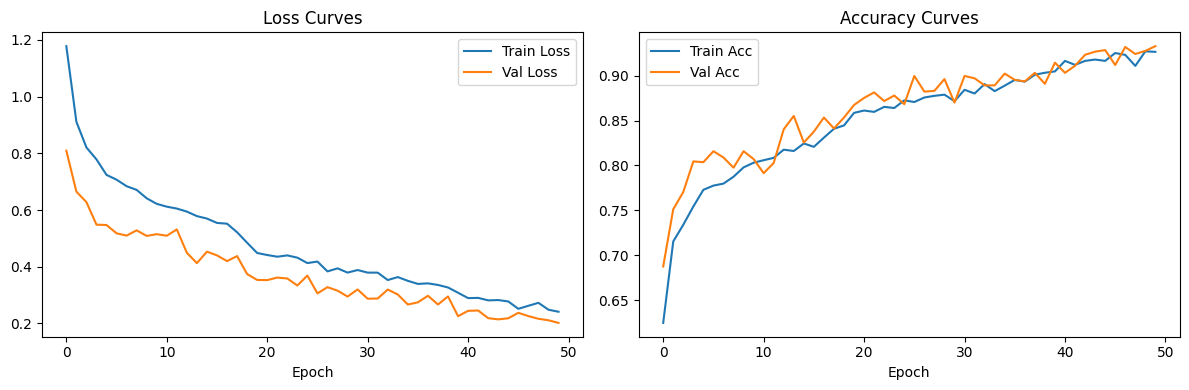


Final Test Macro-F1 Score: 0.9321

                                precision    recall  f1-score   support

Corn_Cercospora_Gray_Leaf_Spot       0.88      0.90      0.89        78
              Corn_Common_Rust       1.00      0.99      1.00       180
     Corn_Northern_Leaf_Blight       0.94      0.93      0.94       149
                  Corn_Healthy       1.00      1.00      1.00       175
    Rice_Bacterial_Leaf_Blight       0.91      0.93      0.92        96
               Rice_Brown_Spot       0.93      0.81      0.86        98
               Rice_Leaf_Blast       0.84      0.92      0.88        96
               Rice_Leaf_Scald       0.94      0.94      0.94        95
            Rice_Sheath_Blight       0.99      0.92      0.95        96
                  Rice_Healthy       0.92      1.00      0.96        99

                      accuracy                           0.94      1162
                     macro avg       0.93      0.93      0.93      1162
                  weighted

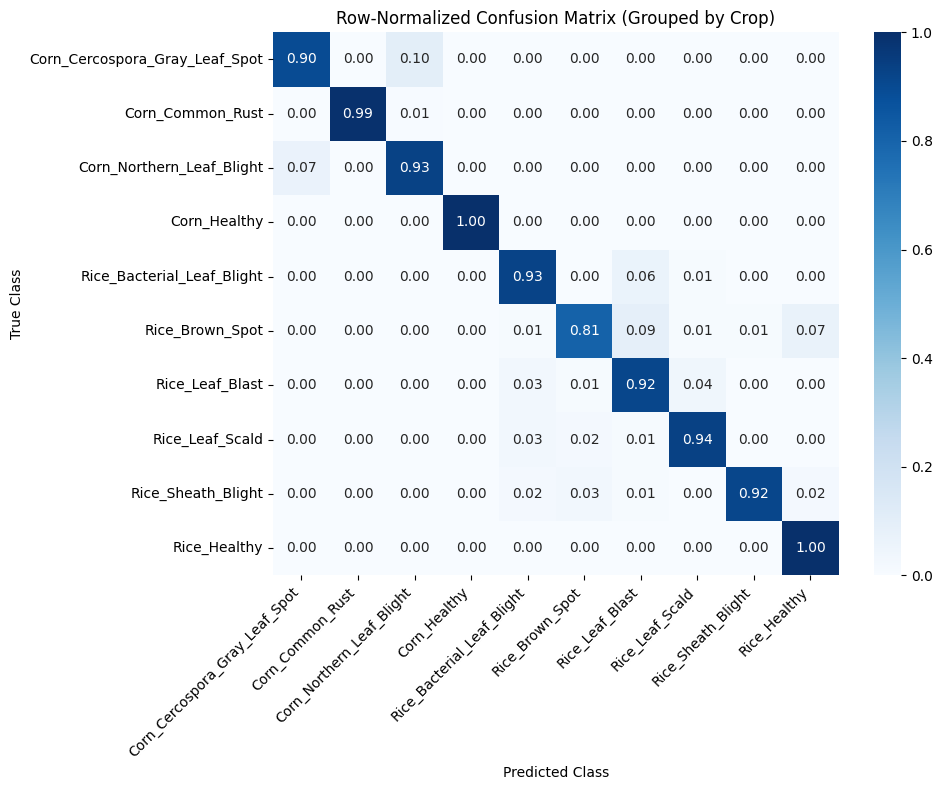


--- Notable Confusions (>= 10% of a class's true images) ---
  Corn_Cercospora_Gray_Leaf_Spot -> predicted as Corn_Northern_Leaf_Blight: 10.3% of true samples. This confusion is within the same crop (expected, visually similar diseases).


In [22]:
# ==============================================================================
# CROP DISEASE DETECTION — FULL PIPELINE (Modules 1-7)
# Run this in a single Kaggle notebook. Paste each "# === MODULE N ===" section
# into its own cell, or run as one script.
#
# Fixes applied vs. the previous version:
#   1. Near-duplicate detection via perceptual hashing (not just exact MD5 dupes)
#   2. EDA step added before splitting (class counts, sample grid, image stats)
#   3. Group-aware split: near-duplicate clusters kept together across splits
#   4. Dataset-specific normalization (computed from our own training data,
#      not borrowed ImageNet stats — there's no pretrained backbone anymore)
#   5. Confusion matrix: added technique 4 (flagging + templated annotation
#      of notable off-diagonal confusions)
#   6. Resize: kept as plain square resize (224x224) — a deliberate choice,
#      consistent with the "keep preprocessing simple" decision. Note: this
#      stretches non-square images rather than preserving aspect ratio. If a
#      visual check of your images shows significant distortion, aspect-
#      preserving padding can be swapped in here instead.
# ==============================================================================

# === MODULE 1: REPRODUCIBILITY & ENVIRONMENT ===
import os
import random
import copy
import subprocess
from collections import defaultdict

from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# imagehash is used for near-duplicate detection (Fix #1). Install if missing.
try:
    import imagehash
except ImportError:
    subprocess.run(["pip", "install", "-q", "imagehash"], check=True)
    import imagehash

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


# === MODULE 2: DATA ACQUISITION ===
PLANTVILLAGE_DIR = "/kaggle/working/PlantVillage-Dataset"
if not os.path.exists(PLANTVILLAGE_DIR):
    print("Cloning raw PlantVillage repository from GitHub...")
    subprocess.run([
        "git", "clone", "https://github.com/spMohanty/PlantVillage-Dataset.git", PLANTVILLAGE_DIR
    ], check=True)
    print("PlantVillage dataset cloned successfully.")

CLASSES = [
    # Corn Classes (Block 1)
    'Corn_Cercospora_Gray_Leaf_Spot',
    'Corn_Common_Rust',
    'Corn_Northern_Leaf_Blight',
    'Corn_Healthy',
    # Rice Classes (Block 2)
    'Rice_Bacterial_Leaf_Blight',
    'Rice_Brown_Spot',
    'Rice_Leaf_Blast',
    'Rice_Leaf_Scald',
    'Rice_Sheath_Blight',
    'Rice_Healthy'
]
class_to_idx = {cls_name: i for i, cls_name in enumerate(CLASSES)}

RICE_ROOT = '/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG'
# NOTE: "AUG" in the folder name is misleading — verified via per-class image
# counts (628-653 per class, 3,829 total) that this matches the known clean
# version of the dataset (anshulm257/rice-disease-dataset), not a heavily
# augmented copy. Folder names below use spaces and inconsistent casing,
# copied exactly as confirmed via os.walk().

data_directory_mapping = {
    # Corn: names confirmed against the actual cloned PlantVillage repo —
    # they include "(maize)" and a TRIPLE underscore, not "Corn___".
    'Corn_Cercospora_Gray_Leaf_Spot': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'),
    'Corn_Common_Rust': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___Common_rust_'),
    'Corn_Northern_Leaf_Blight': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___Northern_Leaf_Blight'),
    'Corn_Healthy': os.path.join(PLANTVILLAGE_DIR, 'raw/color/Corn_(maize)___healthy'),
    # Rice: paths confirmed via os.walk() against the actual mounted dataset
    'Rice_Bacterial_Leaf_Blight': os.path.join(RICE_ROOT, 'Bacterial Leaf Blight'),
    'Rice_Brown_Spot': os.path.join(RICE_ROOT, 'Brown Spot'),
    'Rice_Leaf_Blast': os.path.join(RICE_ROOT, 'Leaf Blast'),
    'Rice_Leaf_Scald': os.path.join(RICE_ROOT, 'Leaf scald'),
    'Rice_Sheath_Blight': os.path.join(RICE_ROOT, 'Sheath Blight'),
    'Rice_Healthy': os.path.join(RICE_ROOT, 'Healthy Rice Leaf'),
}


# === MODULE 3a: COLLECTION + NEAR-DUPLICATE DETECTION (Fix #1) ===
def compute_phash(filepath):
    """Perceptual hash — similar (not just byte-identical) images hash close together."""
    with Image.open(filepath) as img:
        return imagehash.phash(img.convert('RGB'))

def collect_and_group_data(data_dir_map, hash_distance_threshold=5):
    """
    Scans dataset directories, computes a perceptual hash per image, and
    assigns a 'group_id' such that near-duplicate images (hash distance <=
    threshold) share the same group. This group_id is later used to make
    sure near-duplicates never get split across train/val/test (Fix #3).
    """
    records = []
    for target_class, folder_path in data_dir_map.items():
        if not os.path.exists(folder_path):
            print(f"Warning: Directory not found: {folder_path}")
            continue
        for root, _, files in os.walk(folder_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    full_path = os.path.join(root, file)
                    try:
                        phash = compute_phash(full_path)
                    except Exception as e:
                        print(f"Skipping unreadable file {full_path}: {e}")
                        continue
                    records.append({
                        'filepath': full_path,
                        'label_name': target_class,
                        'label_idx': class_to_idx[target_class],
                        'phash': phash
                    })

    df = pd.DataFrame(records)
    if df.empty:
        raise ValueError(
            "No images were found in any of the specified directories. "
            "Check that data_directory_mapping paths are correct, and that "
            "the rice dataset is attached as a Kaggle input (see 'Add Input' "
            "in the notebook's right-hand panel) before re-running."
        )
    print(f"Total images scanned: {len(df)}")

    # Cluster near-duplicates within each class (cross-class hash collisions
    # are not disease-relevant, so clustering is done per class).
    df['group_id'] = -1
    next_group_id = 0
    for label_idx, class_df in df.groupby('label_idx'):
        hashes = class_df['phash'].tolist()
        indices = class_df.index.tolist()
        assigned = {}
        for i, idx_i in enumerate(indices):
            if idx_i in assigned:
                continue
            assigned[idx_i] = next_group_id
            for j in range(i + 1, len(indices)):
                idx_j = indices[j]
                if idx_j in assigned:
                    continue
                if hashes[i] - hashes[j] <= hash_distance_threshold:
                    assigned[idx_j] = next_group_id
            next_group_id += 1
        for idx, gid in assigned.items():
            df.loc[idx, 'group_id'] = gid

    n_groups = df['group_id'].nunique()
    n_dupe_groups = df.groupby('group_id').size().gt(1).sum()
    print(f"Unique near-duplicate groups: {n_groups}")
    print(f"Groups containing 2+ images (i.e. had near-duplicates removed from being 'independent'): {n_dupe_groups}")
    return df

df_all = collect_and_group_data(data_directory_mapping)


# === MODULE 3b: EDA — CLASS COUNTS, SAMPLE GRID, IMAGE PROPERTIES (Fix #2) ===
print("\n--- Class Distribution ---")
class_counts_table = df_all['label_name'].value_counts().reindex(CLASSES)
print(class_counts_table)

plt.figure(figsize=(10, 5))
sns.barplot(x=class_counts_table.values, y=class_counts_table.index)
plt.title("Class Distribution (Post-Deduplication)")
plt.xlabel("Image Count")
plt.tight_layout()
plt.savefig("eda_class_distribution.png")
plt.show()

print("\n--- Sample Grid Per Class ---")
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 3 * len(CLASSES)))
for i, cls in enumerate(CLASSES):
    samples = df_all[df_all['label_name'] == cls].sample(n=min(4, len(df_all[df_all['label_name'] == cls])), random_state=SEED)
    for j, (_, row) in enumerate(samples.iterrows()):
        img = Image.open(row['filepath'])
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(cls, fontsize=8)
    for j in range(len(samples), 4):
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig("eda_sample_grid.png")
plt.show()

print("\n--- Image Property Check (resolution/aspect ratio sample) ---")
prop_sample = df_all.sample(n=min(200, len(df_all)), random_state=SEED)
sizes = []
for _, row in prop_sample.iterrows():
    with Image.open(row['filepath']) as img:
        sizes.append(img.size)  # (width, height)
widths, heights = zip(*sizes)
print(f"Width  -> min: {min(widths)}, max: {max(widths)}, mean: {np.mean(widths):.0f}")
print(f"Height -> min: {min(heights)}, max: {max(heights)}, mean: {np.mean(heights):.0f}")
aspect_ratios = [w / h for w, h in sizes]
print(f"Aspect ratio -> min: {min(aspect_ratios):.2f}, max: {max(aspect_ratios):.2f} "
      f"(1.0 = square; large spread here means the Resize-to-square step below will distort some images more than others)")


# === MODULE 3c: GROUP-AWARE STRATIFIED SPLIT (Fix #3) ===
def group_aware_stratified_split(df, test_size=0.30, val_ratio_of_temp=0.50, seed=SEED):
    """
    Splits the data 70/15/15 (by default) while:
      - keeping every near-duplicate group entirely within one split
      - keeping per-class proportions close to the target ratios
    This is a manual per-class group allocator since sklearn doesn't offer
    a single built-in stratified+grouped train/val/test split.
    """
    rng = random.Random(seed)
    train_idx, val_idx, test_idx = [], [], []

    for label_idx, class_df in df.groupby('label_idx'):
        groups = class_df.groupby('group_id')
        group_list = list(groups.groups.items())  # [(group_id, [row_indices]), ...]
        rng.shuffle(group_list)

        total_n = len(class_df)
        target_train = total_n * (1 - test_size)
        target_val = total_n * test_size * (1 - val_ratio_of_temp)
        # (target_test is whatever remains)

        running_train, running_val = 0, 0
        for gid, idxs in group_list:
            n = len(idxs)
            if running_train + n <= target_train or running_train == 0:
                train_idx.extend(idxs)
                running_train += n
            elif running_val + n <= target_val or running_val == 0:
                val_idx.extend(idxs)
                running_val += n
            else:
                test_idx.extend(idxs)

    train_df = df.loc[train_idx].reset_index(drop=True)
    val_df = df.loc[val_idx].reset_index(drop=True)
    test_df = df.loc[test_idx].reset_index(drop=True)
    return train_df, val_df, test_df

train_df, val_df, test_df = group_aware_stratified_split(df_all)

print(f"\nSplits -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
print("\nPer-class split breakdown:")
split_check = pd.DataFrame({
    'train': train_df['label_name'].value_counts().reindex(CLASSES).fillna(0),
    'val': val_df['label_name'].value_counts().reindex(CLASSES).fillna(0),
    'test': test_df['label_name'].value_counts().reindex(CLASSES).fillna(0),
})
print(split_check)

# Sanity check: confirm no group_id appears in more than one split
train_groups = set(train_df['group_id'])
val_groups = set(val_df['group_id'])
test_groups = set(test_df['group_id'])
overlap = (train_groups & val_groups) | (train_groups & test_groups) | (val_groups & test_groups)
assert len(overlap) == 0, f"Leakage detected: {len(overlap)} group(s) span multiple splits!"
print("\nLeakage check passed: no near-duplicate group spans multiple splits.")

# Class weights (computed on train split only)
class_counts = train_df['label_idx'].value_counts().sort_index().values
total_samples = len(train_df)
class_weights = total_samples / (len(CLASSES) * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)


# === MODULE 3d: DATASET-SPECIFIC NORMALIZATION STATS (Fix #4) ===
def compute_mean_std(df, sample_size=2000, img_size=224):
    """
    Computes per-channel mean/std from our own training images, since there's
    no pretrained backbone to borrow ImageNet stats from (Fix #4).
    """
    sample = df.sample(n=min(sample_size, len(df)), random_state=SEED)
    basic_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor()
    ])
    channel_sum = torch.zeros(3)
    channel_sq_sum = torch.zeros(3)
    n_pixels = 0

    for _, row in sample.iterrows():
        img = Image.open(row['filepath']).convert('RGB')
        tensor = basic_transform(img)
        channel_sum += tensor.sum(dim=[1, 2])
        channel_sq_sum += (tensor ** 2).sum(dim=[1, 2])
        n_pixels += tensor.shape[1] * tensor.shape[2]

    mean = channel_sum / n_pixels
    std = torch.sqrt(channel_sq_sum / n_pixels - mean ** 2)
    return mean.tolist(), std.tolist()

print("\nComputing dataset-specific normalization stats from training split...")
DATASET_MEAN, DATASET_STD = compute_mean_std(train_df)
print(f"Dataset mean: {DATASET_MEAN}")
print(f"Dataset std:  {DATASET_STD}")


# === MODULE 4: TRANSFORMS & DATASET PIPELINE ===
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=DATASET_MEAN, std=DATASET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=DATASET_MEAN, std=DATASET_STD)
])

class CropDiseaseDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = self.df.loc[idx, 'label_idx']
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

train_loader = DataLoader(CropDiseaseDataset(train_df, train_transform), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(CropDiseaseDataset(val_df, eval_transform), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(CropDiseaseDataset(test_df, eval_transform), batch_size=32, shuffle=False, num_workers=2)


# === MODULE 5: SCRATCH CNN ARCHITECTURE ===
class ScratchCropCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(ScratchCropCNN, self).__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)

model = ScratchCropCNN(num_classes=10).to(device)


# === MODULE 6: TRAINING ROUTINE (ADAM ONLY) ===
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999))
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

print("\n--- Starting Model Training (Adam Optimizer, LR=1e-3) ---")
best_loss = float('inf')
best_model_wts = copy.deepcopy(model.state_dict())
patience, patience_counter = 8, 0
epochs = 50

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    t_loss, t_acc = train_epoch(model, train_loader, optimizer, criterion)
    v_loss, v_acc = evaluate(model, val_loader, criterion)

    scheduler.step(v_loss)

    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_acc'].append(t_acc)
    history['val_acc'].append(v_acc)

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {t_loss:.4f} Acc: {t_acc:.4f} | Val Loss: {v_loss:.4f} Acc: {v_acc:.4f} | LR: {current_lr:.6f}")

    if v_loss < best_loss:
        best_loss = v_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1}")
            break

model.load_state_dict(best_model_wts)
torch.save(model.state_dict(), "crop_disease_scratch_cnn.pth")
print("Best model weights saved as 'crop_disease_scratch_cnn.pth'")

# Save normalization stats alongside the model — the Streamlit app needs
# these exact values to preprocess inference images identically (Module 8
# requires preprocessing consistency with training).
with open("normalization_stats.txt", "w") as f:
    f.write(f"mean={DATASET_MEAN}\nstd={DATASET_STD}\n")

# Training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title("Loss Curves")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Acc')
plt.plot(history['val_acc'], label='Val Acc')
plt.title("Accuracy Curves")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.savefig("training_curves.png")
plt.show()


# === MODULE 7: EVALUATION & EXPLAINABLE CONFUSION MATRIX ===
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

macro_f1 = f1_score(all_labels, all_preds, average='macro')
print(f"\nFinal Test Macro-F1 Score: {macro_f1:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=CLASSES))

# Technique 1 + 2: row-normalized, crop-grouped (CLASSES is already ordered
# corn-block then rice-block, so the axis order below gives that grouping)
cm = confusion_matrix(all_labels, all_preds, normalize='true')

# Technique 3: heatmap styling
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Row-Normalized Confusion Matrix (Grouped by Crop)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# Technique 4: flag and annotate notable off-diagonal confusions (Fix #5)
CONFUSION_FLAG_THRESHOLD = 0.10  # flag if >=10% of a class's images go to one wrong class
print("\n--- Notable Confusions (>= 10% of a class's true images) ---")
notable_confusions = []
for i, true_cls in enumerate(CLASSES):
    for j, pred_cls in enumerate(CLASSES):
        if i != j and cm[i, j] >= CONFUSION_FLAG_THRESHOLD:
            notable_confusions.append((true_cls, pred_cls, cm[i, j]))

if not notable_confusions:
    print("None found above threshold — classes are being cleanly separated.")
else:
    for true_cls, pred_cls, rate in sorted(notable_confusions, key=lambda x: -x[2]):
        same_crop = true_cls.split('_')[0] == pred_cls.split('_')[0]
        scope_note = "within the same crop (expected, visually similar diseases)" \
            if same_crop else "ACROSS crops (worth investigating — possible shortcut learning, e.g. background/leaf-shape cues rather than lesion patterns)"
        print(f"  {true_cls} -> predicted as {pred_cls}: {rate*100:.1f}% of true samples. "
              f"This confusion is {scope_note}.")
        # NOTE: the scope_note above is auto-generated from class/crop labels only.
        # Replace/extend with your own domain-specific reasoning (e.g. "both
        # present as elongated grey-brown lesions") once you've visually
        # compared the confused classes yourself.